# CyberLens - Cybercrime Complaint and Scam Call Classifier

This notebook shows how I built and ran the CyberLens classifier, step by step.

The project has two classifiers:
1. Complaint classifier - English cybercrime complaints (train.csv / test.csv), 39 labels of the form `category :: sub_category`.
2. Call scam classifier - Hinglish scam call messages (India_Cyber_Scam_Hinglish_Dataset.csv), 4 labels: police_digital_arrest, police_blackmail, other_scam and none.

All the actual code is in the `cyberlens/` folder. In this notebook I import those functions instead of copying them, so the results here are from the same code that `run.ps1` and the web app (`app.py`) use.

Order of the notebook:
1. Loading the datasets
2. Data cleaning and the train/validation/test split
3. Preprocessing (masking, fingerprint, typos)
4. Training a TF-IDF baseline
5. Loading my saved models and checking the results
6. Confidence threshold (0.975)
7. Predictions on example complaints with explanation
8. Commands I used to run everything

Training the full models takes a long time, so by default I load the saved models from `models/`. To retrain, set `RUN_HEAVY_TRAINING = True` in the next cell.

## Setup

Importing the libraries and setting the project folder. The notebook is inside `notebooks/`, so I move one folder up to the project root so that `cyberlens`, `data/`, `models/` and `reports/` can be found.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, torch

# go to the project root (one level above notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# set True only if you want to retrain the saved models (slow, ~15-20 min on CPU)
RUN_HEAVY_TRAINING = False

pd.set_option("display.max_colwidth", 90)

print("Project root:", ROOT)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available, using CPU")

Project root: C:\Users\chait\Downloads\Projects\NLP\CyberLens_Classifier
Python 3.12.14 | pandas 3.0.5 | sklearn 1.9.1 | torch 2.14.0+cu126
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Loading the datasets

The raw files are in `data/raw/`. I am not printing the complaint text because these are real complaints, so I only show the shape and columns.

In [2]:
raw_train = pd.read_csv("data/raw/train.csv")
raw_test = pd.read_csv("data/raw/test.csv")
raw_call = pd.read_csv("data/raw/India_Cyber_Scam_Hinglish_Dataset.csv")

print("train.csv :", raw_train.shape)
print("test.csv  :", raw_test.shape)
print("hinglish  :", raw_call.shape)
print()
print("complaint columns:", list(raw_train.columns))
print("call columns     :", list(raw_call.columns))

train.csv : (93686, 3)
test.csv  : (31229, 3)
hinglish  : (10000, 8)

complaint columns: ['category', 'sub_category', 'crimeaditionalinfo']
call columns     : ['text', 'label', 'scam_category', 'caller_type', 'audio_duration', 'urgency_level', 'contains_blackmail', 'language_style']


The Hinglish call dataset is synthetic dialogue, so it is fine to look at a few rows.

In [3]:
raw_call[["text", "scam_category", "language_style"]].head()

,text,scam_category,language_style
0,"Hello ji Beta ghar aa gaya hoon, darwaza khol do.",none,hinglish
1,Namaste ma'am Project ka review meeting kal 4 baje hai kya?,none,hinglish
2,Ji namaskar Aapka KYC pending hai. Account 2 ghante mein block ho jayega. OTP share ki...,relative,hinglish
3,"Ji namaskar Doctor appointment kal 9 baje hai, fasting rehna.",none,hinglish
4,Special Investigation Team se bol raha hoon. Amazon se bol raha hoon. Aapka parcel hol...,bank_kyc,hinglish


For the complaint data the label is made by joining category and sub_category, because some sub_category names repeat under different categories. Missing sub_category becomes "Unspecified".

In [4]:
labels_raw = raw_train["category"].str.strip() + " :: " + raw_train["sub_category"].fillna("Unspecified").str.strip()

print("categories     :", raw_train["category"].nunique())
print("sub categories :", raw_train["sub_category"].nunique())
print("combined labels:", labels_raw.nunique())
print("missing text   :", raw_train["crimeaditionalinfo"].isnull().sum())

categories     : 15
sub categories : 35
combined labels: 40
missing text   : 21


## 2. Data cleaning and splitting

This is done by `prepare(protocol="official")` in `cyberlens/data.py`. The steps are:

- normalise and mask the text (section 3), and drop texts shorter than 5 characters
- make a fingerprint of every text, so complaints that are the same apart from numbers or punctuation are treated as one template
- if one template has different labels, keep the majority label when it covers at least 60% of the rows, otherwise drop that template
- remove duplicate copies of the same template
- drop labels with less than 10 examples
- split 80/20 into train and validation (stratified), with no template in both

test.csv is kept as it is (only empty or very short rows removed) and is not used while cleaning the training data.

I am not running `prepare()` again here because it overwrites the processed files. Instead I read the counts it saved in `reports/data_audit_official.json`.

In [5]:
audit = json.loads(Path("reports/data_audit_official.json").read_text())["complaint_official"]

raw_rows = audit["raw_rows"]
short = audit["empty_or_short_rows_excluded"]
conflict = audit["conflicting_rows_excluded"]
dupes = audit["duplicate_rows_removed"]
rare = sum(audit["rare_labels_excluded"].values())

# going from raw rows to unique complaints
print(f"raw rows in train.csv                {raw_rows:>7,}")
print(f"- empty / too short                  {short:>7,}")
print(f"- conflicting labels (no majority)   {conflict:>7,}")
print(f"- duplicate templates                {dupes:>7,}")
print(f"- rare labels (<10 examples)         {rare:>7,}")
print(f"= unique complaints                  {raw_rows - short - conflict - dupes - rare:>7,}")
print()
print("templates fixed by majority vote:", audit["conflicting_groups_resolved_by_majority"],
      f"({audit['conflicting_rows_resolved_by_majority']} rows)")

raw rows in train.csv                 93,686
- empty / too short                    1,409
- conflicting labels (no majority)     1,571
- duplicate templates                 11,594
- rare labels (<10 examples)               1
= unique complaints                   79,111

templates fixed by majority vote: 141 (4663 rows)


Now loading the processed file that `prepare()` wrote, and checking the split sizes.

In [6]:
from cyberlens.data import load

df = load("complaint", protocol="official")
print(df["split"].value_counts())

n_train = (df["split"] == "train").sum()
n_val = (df["split"] == "validation").sum()
n_test = (df["split"] == "test").sum()
print()
print(f"train + validation = {n_train + n_val:,} unique complaints")
print(f"test = {n_test:,} usable rows out of {len(raw_test):,} in test.csv")
print("number of labels =", df.loc[df["split"] == "train", "label"].nunique())

split
train         63288
test          30771
validation    15823
Name: count, dtype: int64

train + validation = 79,111 unique complaints
test = 30,771 usable rows out of 31,229 in test.csv
number of labels = 39


Class distribution of the training split. The classes are very imbalanced, so I use macro-F1 (average F1 over all labels) as the main metric instead of only accuracy. Accuracy would look good just by predicting the big classes.

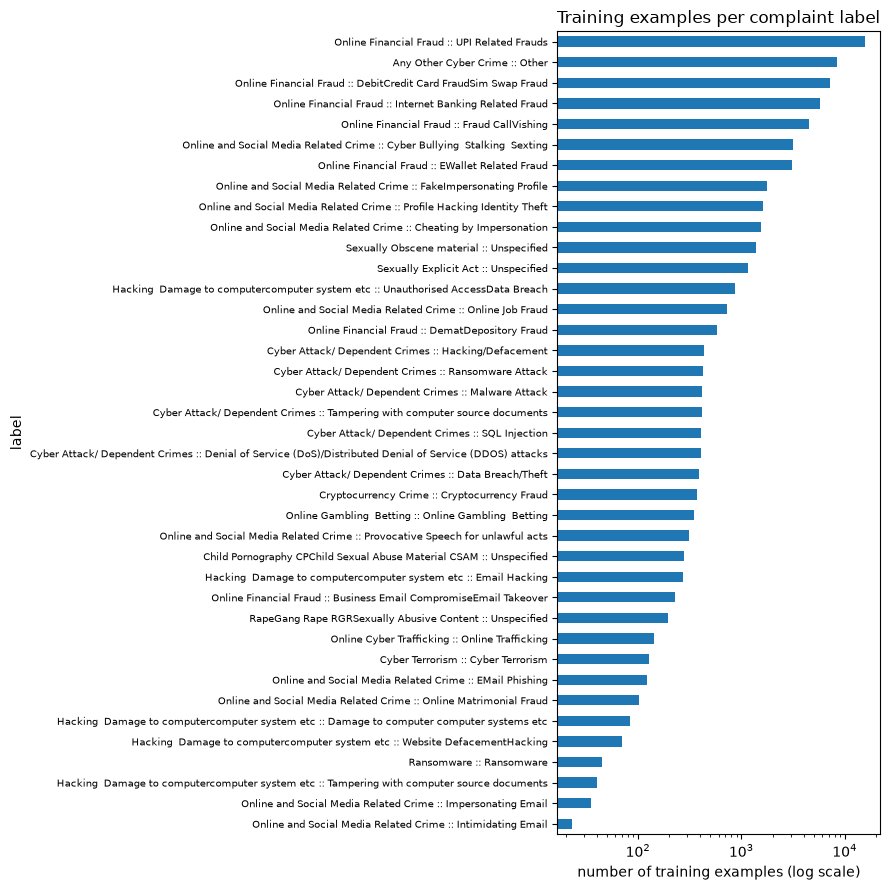

largest class : 15806
smallest class: 23


In [7]:
counts = df.loc[df["split"] == "train", "label"].value_counts()

fig, ax = plt.subplots(figsize=(9, 9))
counts.sort_values().plot.barh(ax=ax)
ax.set_xscale("log")   # log scale, otherwise the small classes are not visible
ax.set_xlabel("number of training examples (log scale)")
ax.set_title("Training examples per complaint label")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

print("largest class :", counts.iloc[0])
print("smallest class:", counts.iloc[-1])

## 3. Preprocessing

The preprocessing functions are in `cyberlens/preprocessing.py`. I am showing them on my own made-up examples.

### 3.1 normalize()

This does Unicode normalisation, removes zero width characters and extra spaces, and masks sensitive values like URLs, emails, UPI IDs, PAN, Aadhaar, phone numbers, and numbers after words like OTP, PIN, account or card. Masking is rule based, so names and addresses are not removed.

In [8]:
from cyberlens.preprocessing import normalize, fingerprint, corrupt, tokens

examples = [
    "Call me on +91 98765 43210, my UPI is ramesh.k@okaxis",
    "Your OTP is 482913. Do not share. Visit www.fake-kyc.in now",
    "Bhai mera account number 123456789012 hai, card no 4111 1111 1111 1111",
]

for text in examples:
    print("before:", text)
    print("after :", normalize(text))
    print()

before: Call me on +91 98765 43210, my UPI is ramesh.k@okaxis
after : Call me on <PHONE>, my UPI is <UPI_ID>

before: Your OTP is 482913. Do not share. Visit www.fake-kyc.in now
after : Your OTP is <OTP>. Do not share. Visit <URL> now

before: Bhai mera account number 123456789012 hai, card no 4111 1111 1111 1111
after : Bhai mera account number <ACCOUNT> hai, card no <CARD>



### 3.2 fingerprint()

The fingerprint lowercases the text, replaces numbers with NUM and ignores punctuation, then hashes it. So two complaints that only differ in amount or date get the same fingerprint. This is what I used to remove duplicates and to make sure the same template is not in both train and validation.

In [9]:
a = "I lost Rs 5000 on 12/03/2024 through a fake UPI request!"
b = "i lost rs 72000 on 01-01-2023 through a fake UPI request"

print("same fingerprint:", fingerprint(a) == fingerprint(b))
print("tokens:", tokens(normalize(a)))

same fingerprint: True
tokens: ['i', 'lost', 'rs', '5000', 'on', '12', '03', '2024', 'through', 'a', 'fake', 'upi', 'request']


### 3.3 corrupt()

This swaps two letters inside some words to make fake typos. I use it to make a typo version of the validation and test sets, to check if the model still works with spelling mistakes.

In [10]:
text = "Someone called pretending to be from the bank and asked for my password"
print("original:", text)
print("typos   :", corrupt(text, seed=1, rate=0.25))

original: Someone called pretending to be from the bank and asked for my password
typos   : Smoeone called pretending to be from the bank and asked for my password


## 4. Training a TF-IDF baseline

The model is made by `make_model()` in `cyberlens/baseline.py`. It is TF-IDF features + a linear classifier (logistic regression trained with SGD, with balanced class weights). There are three versions:
- word: word 1-2 grams
- char: character 3-5 grams (better for typos and Hinglish spellings)
- hybrid: both together

Here I train the word version on the training split and test it on the validation split. It takes around 1-2 minutes on CPU. In the full run all three versions are trained and the best one on validation is kept (the test set is not used to choose).

In [11]:
from cyberlens.baseline import make_model
from cyberlens.metrics import score

train = df[df["split"] == "train"]
valid = df[df["split"] == "validation"]
test = df[df["split"] == "test"]
labels = sorted(train["label"].unique())

model = make_model("word")
model.set_params(classifier__n_jobs=1)   # 1 thread so the laptop CPU does not overheat
print(model)

start = time.perf_counter()
model.fit(train["text"], train["label"])
print(f"\ntrained on {len(train):,} complaints in {time.perf_counter() - start:.0f} seconds")

Pipeline(steps=[('features',
                 TfidfVectorizer(dtype=<class 'numpy.float32'>,
                                 max_features=65000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 SGDClassifier(alpha=1e-05, average=True,
                               class_weight='balanced', loss='log_loss',
                               max_iter=80, n_jobs=1, random_state=42,
                               tol=0.0001))])



trained on 63,288 complaints in 38 seconds


Evaluating on the validation set, once on the clean text and once on the typo version.

In [12]:
# clean validation
clean = score(valid["label"], model.predict(valid["text"].tolist()), labels)

# validation with fake typos in 25% of the words
noisy_text = [corrupt(t, seed=42 + i, rate=0.25) for i, t in enumerate(valid["text"])]
noisy = score(valid["label"], model.predict(noisy_text), labels)

print(f"validation        macro-F1 = {clean['macro_f1']:.4f}   accuracy = {clean['accuracy']:.4f}")
print(f"validation typos  macro-F1 = {noisy['macro_f1']:.4f}   accuracy = {noisy['accuracy']:.4f}")

validation        macro-F1 = 0.2528   accuracy = 0.4825
validation typos  macro-F1 = 0.2509   accuracy = 0.4715


Checking which words the model learned for two of the labels. A higher coefficient means the word pushes the prediction more towards that label.

In [13]:
words = model.named_steps["features"].get_feature_names_out()
coef = model.named_steps["classifier"].coef_
print("vocabulary size:", len(words))

for label in ["Online Financial Fraud :: UPI Related Frauds", "Online and Social Media Related Crime :: Online Job Fraud"]:
    row = list(model.classes_).index(label)
    top = np.argsort(coef[row])[::-1][:12]   # 12 highest weights
    print("\n" + label)
    print("  ", ", ".join(words[top]))

vocabulary size: 65000

Online Financial Fraud :: UPI Related Frauds
   upi, phonepe, through upi, upi fraud, phone pe, pe, victim, pe bank, money, pay, amount, fraud

Online and Social Media Related Crime :: Online Job Fraud
   job, work, company, interview, technologies, registration, jobs, login, mail, url, job in, ekart


### Full retraining (optional)

This is the same as running `.\run.ps1 train --backend baseline` and `.\run.ps1 train --task complaint --backend adjusted`. It overwrites the saved models, so it only runs when `RUN_HEAVY_TRAINING = True`.

In [14]:
if RUN_HEAVY_TRAINING:
    from cyberlens import baseline, adjusted
    baseline.train(("complaint",))   # trains word, char and hybrid and keeps the best
    adjusted.train()                 # official protocol + class prior correction
else:
    print("skipped, using the saved models in models/")

skipped, using the saved models in models/


## 5. Saved models and results

All trained models are saved in `models/` and all evaluation results in `reports/` as JSON. The three complaint models I compare are:

- baseline: TF-IDF hybrid + SGD (`complaint_baseline.joblib`)
- adjusted: same features but trained on the full official training data, plus a class prior correction (`complaint_adjusted.joblib`). Balanced class weights made the rare labels get predicted too often, so I add tau x log(prior) to the log probabilities. alpha and tau were chosen on validation.
- fusion (final model): fine-tuned xlm-roberta-base encoder combined with the adjusted model, 0.4 x encoder + 0.6 x sparse (`complaint_fusion.joblib` and `complaint_fusion_encoder/`)

List of everything in the models folder:

In [15]:
for path in sorted(Path("models").iterdir()):
    if path.is_dir():
        size = sum(f.stat().st_size for f in path.rglob("*"))
    else:
        size = path.stat().st_size
    print(f"{path.name:<40} {size / 1e6:>8.1f} MB")

call_scam_baseline.joblib                     0.0 MB
call_scam_robust.joblib                       0.0 MB
call_scam_subword.joblib                      1.0 MB
call_scam_transformer                       544.2 MB
call_scam_word2vec.joblib                     0.1 MB
champions.json                                0.0 MB
complaint_adjusted.joblib                    72.7 MB
complaint_baseline.joblib                    72.2 MB
complaint_continued                         544.4 MB
complaint_ensemble.joblib                    72.4 MB
complaint_fusion.joblib                      72.7 MB
complaint_fusion_encoder                   1129.4 MB
complaint_hierarchical.joblib                76.5 MB
complaint_hing_fusion.joblib                 72.7 MB
complaint_hing_fusion_encoder              1129.4 MB
complaint_hing_fusion_smoke_encoder           9.3 MB
complaint_margin.joblib                      32.6 MB
complaint_regularized.joblib                 49.9 MB
complaint_semantic.joblib                     

### 5.1 Checking a saved result again

To make sure the numbers in the report are real, I load the saved adjusted model and run it on all the test complaints. The result should match `reports/complaint_adjusted.json`. This takes about a minute on CPU.

In [16]:
bundle = joblib.load("models/complaint_adjusted.joblib")
adjusted_model = bundle["model"]

start = time.perf_counter()
test_probs = adjusted_model.predict_proba(test["text"].tolist())
test_pred = adjusted_model.classes_[test_probs.argmax(axis=1)]
print(f"predicted {len(test):,} test complaints in {time.perf_counter() - start:.0f} seconds")

test_labels = sorted(set(train["label"]) | set(test["label"]))
now = score(test["label"], test_pred, test_labels)

saved = json.loads(Path("reports/complaint_fusion.json").read_text())["adjusted_results"]["test"]
print(f"computed now : macro-F1 = {now['macro_f1']:.4f}   accuracy = {now['accuracy']:.4f}")
print(f"saved report : macro-F1 = {saved['macro_f1']:.4f}   accuracy = {saved['accuracy']:.4f}")

predicted 30,771 test complaints in 19 seconds


computed now : macro-F1 = 0.2640   accuracy = 0.5514
saved report : macro-F1 = 0.2640   accuracy = 0.5514


### 5.2 Comparing the three models

All three are tested on the same official test rows. I also report three harder versions of the test set:
- typos: fake spelling mistakes added
- unique templates: each repeated template counted only once
- novel templates: only test complaints whose template is not in train.csv at all (the hardest one)

In [17]:
fusion = json.loads(Path("reports/complaint_fusion.json").read_text())
baseline_slices = json.loads(Path("reports/complaint_baseline_slices.json").read_text())

slices = {"test": "full test", "test_typos": "test with typos",
          "test_unique_examples": "unique templates", "test_novel_templates": "novel templates"}

rows = []
for key, name in slices.items():
    b = baseline_slices[key]
    a = fusion["adjusted_results"][key]
    f = fusion["test_results"][key]
    rows.append([name, f["n"], b["macro_f1"], a["macro_f1"], f["macro_f1"], b["accuracy"], a["accuracy"], f["accuracy"]])

results = pd.DataFrame(rows, columns=["slice", "rows", "baseline F1", "adjusted F1", "fusion F1",
                                      "baseline acc", "adjusted acc", "fusion acc"]).set_index("slice")
results.round(4)

,rows,baseline F1,adjusted F1,fusion F1,baseline acc,adjusted acc,fusion acc
slice,,,,,,,
full test,30771,0.2345,0.2640,0.2745,0.5014,0.5514,0.5617
test with typos,30771,0.2269,0.2586,0.2701,0.4950,0.5474,0.5573
unique templates,27296,0.2384,0.2471,0.2588,0.4884,0.5133,0.5251
novel templates,25757,0.2376,0.2382,0.2524,0.4745,0.4965,0.5094


Plotting the macro-F1 of the three models.

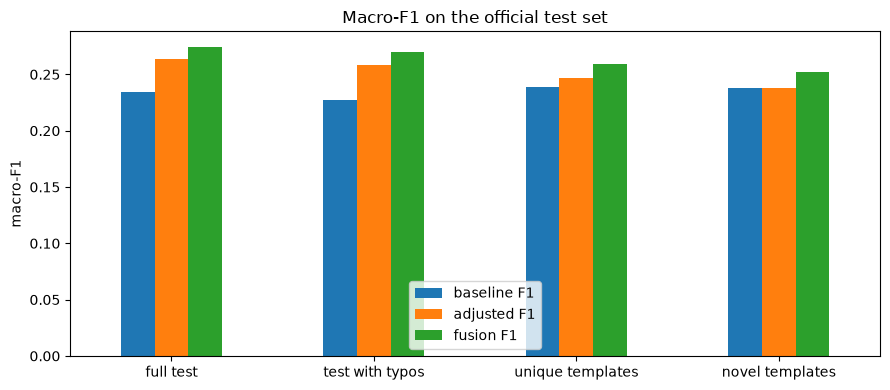

In [18]:
ax = results[["baseline F1", "adjusted F1", "fusion F1"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("macro-F1")
ax.set_xlabel("")
ax.set_title("Macro-F1 on the official test set")
plt.tight_layout()
plt.show()

Is the fusion model really better than the adjusted model, or is it just luck? I checked this with a paired bootstrap (500 resamples, grouped by template). If the 95% interval is above zero, the improvement is not just chance. I also wrote the rule for accepting the new model before running it on test.

In [19]:
ci = fusion["uncertainty_vs_adjusted"]
for key in ["test", "test_novel_templates"]:
    print(slices[key])
    print(f"   macro-F1 gain 95% CI: [{ci[key]['lower_95']:+.4f}, {ci[key]['upper_95']:+.4f}]")
    print(f"   accuracy gain 95% CI: [{ci[key]['accuracy_lower_95']:+.4f}, {ci[key]['accuracy_upper_95']:+.4f}]")

print("\nadoption rule:", fusion["adoption_rule"])
print("adopted:", fusion["adopt"])

full test
   macro-F1 gain 95% CI: [+0.0003, +0.0212]
   accuracy gain 95% CI: [+0.0076, +0.0134]
novel templates
   macro-F1 gain 95% CI: [+0.0040, +0.0225]
   accuracy gain 95% CI: [+0.0097, +0.0156]

adoption rule: Novel-template macro-F1 >= adjusted + 0.01; full-test macro-F1 and accuracy >= adjusted
adopted: True


Macro-F1 of about 0.27 looks low, but it is the average over 39 detailed labels and many of them have very similar wording (for example "Fraud Call/Vishing" and "Internet Banking Related Fraud"). Accuracy is about 56%. The gain of fusion over adjusted is small, but the interval stays above zero for both the full test and the novel templates.

Best and worst labels for the fusion model:

In [20]:
per_class = pd.DataFrame(fusion["test_results"]["test"]["per_class"]).T
per_class = per_class.loc[[c for c in per_class.index if " :: " in c]]   # keep only the real labels, not the averages
per_class = per_class[["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)

print("top 5 labels")
display(per_class.sort_values("f1-score", ascending=False).head(5).round(3))

print("weakest 5 labels (with at least 50 test rows)")
display(per_class[per_class["support"] >= 50].sort_values("f1-score").head(5).round(3))

top 5 labels


,precision,recall,f1-score,support
RapeGang Rape RGRSexually Abusive Content :: Unspecified,0.968,0.925,0.946,911
Online Financial Fraud :: UPI Related Frauds,0.730,0.776,0.752,8739
Online Financial Fraud :: DebitCredit Card FraudSim Swap Fraud,0.711,0.715,0.713,3514
Online Financial Fraud :: Internet Banking Related Fraud,0.675,0.597,0.634,2959
Cryptocurrency Crime :: Cryptocurrency Fraud,0.433,0.842,0.572,165


weakest 5 labels (with at least 50 test rows)


,precision,recall,f1-score,support
Online Cyber Trafficking :: Online Trafficking,0.000,0.00,0.000,61
Cyber Terrorism :: Cyber Terrorism,0.000,0.00,0.000,51
Cyber Attack/ Dependent Crimes :: Data Breach/Theft,0.111,0.07,0.086,171
Cyber Attack/ Dependent Crimes :: Denial of Service (DoS)/Distributed Denial of Service (DDOS) attacks,0.100,0.08,0.089,187
Cyber Attack/ Dependent Crimes :: Malware Attack,0.097,0.10,0.099,170


## 6. Confidence threshold (0.975)

Since the overall accuracy is only about 56%, the app should not show every prediction as sure. So it only says "Very likely" when the top score is at least 0.975. Otherwise it says "Possibly" and asks the user to check with someone or call 1930.

I picked the threshold on the validation set with a fixed rule: the lowest threshold (most complaints answered) where the answered complaints still have macro-F1 of at least 0.5. That came out as 0.9746, which I rounded to 0.975 (`FALLBACK_THRESHOLD` in `cyberlens/ui_helpers.py`).

Here I apply it to the test predictions from section 5.1.

In [21]:
from sklearn.metrics import f1_score
from cyberlens.ui_helpers import FALLBACK_THRESHOLD

confidence = test_probs.max(axis=1)   # top score for each complaint
y_true = test["label"].to_numpy()

def answered(threshold):
    # keep only the complaints where the model is at least this confident
    keep = confidence >= threshold
    yt, yp = y_true[keep], test_pred[keep]
    present = sorted(set(yt) | set(yp))
    return {"threshold": threshold,
            "coverage": keep.mean(),
            "answered": int(keep.sum()),
            "accuracy": (yt == yp).mean(),
            "macro_f1": f1_score(yt, yp, labels=present, average="macro", zero_division=0)}

pd.DataFrame([answered(t) for t in [0.0, 0.5, 0.9, FALLBACK_THRESHOLD]]).set_index("threshold").round(4)

,coverage,answered,accuracy,macro_f1
threshold,,,,
0.000,1.0000,30771,0.5514,0.2640
0.500,0.5364,16505,0.7593,0.4225
0.900,0.1692,5207,0.9412,0.4051
0.975,0.0887,2730,0.9846,0.5641


Plotting coverage against accuracy for many thresholds. As the threshold goes up, fewer complaints are answered but the accuracy goes up a lot.

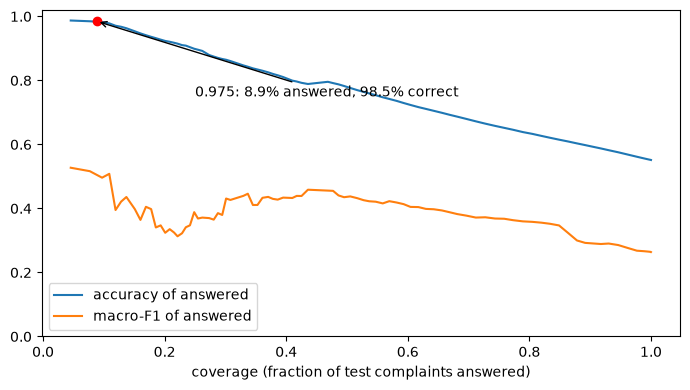

In [22]:
curve = pd.DataFrame([answered(t) for t in np.linspace(0, 0.99, 100)])
point = answered(FALLBACK_THRESHOLD)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["coverage"], curve["accuracy"], label="accuracy of answered")
ax.plot(curve["coverage"], curve["macro_f1"], label="macro-F1 of answered")
ax.scatter(point["coverage"], point["accuracy"], color="red", zorder=3)
ax.annotate(f"0.975: {point['coverage']:.1%} answered, {point['accuracy']:.1%} correct",
            (point["coverage"], point["accuracy"]), xytext=(0.25, 0.75), arrowprops={"arrowstyle": "->"})
ax.set_xlabel("coverage (fraction of test complaints answered)")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

So at 0.975 the model answers about 9% of complaints and is right about 98% of the time on those. The rest go to a human. The threshold was found using the adjusted model, so for the fusion model it is only an approximation.

## 7. Predictions on example complaints

`Predictor` in `cyberlens/predict.py` is used by both the command line and the web app. It masks the text, runs the model and returns the top 3 labels with scores. The `verdict()` function in `cyberlens/ui_helpers.py` combines the complaint model and the call scam model into the final answer shown to the user.

I use the fusion model if it is saved, otherwise the adjusted model. The encoder runs on the GPU if available. The examples are the same ones as the buttons in the app.

In [23]:
from cyberlens.predict import Predictor
from cyberlens.ui_helpers import (EXAMPLES, CONFIDENT_THRESHOLD, classify_both, verdict, friendly,
                                  sparse_model, sparse_explanation)

backend = "fusion" if Path("models/complaint_fusion.joblib").exists() else "adjusted"
predictor = Predictor(backend=backend)
print("complaint model:", backend)
print("threshold:", CONFIDENT_THRESHOLD)

complaint model: fusion
threshold: 0.975


Running all the examples through both models.

In [24]:
rows, outputs = [], []
for ex in EXAMPLES:
    start = time.perf_counter()
    out = classify_both(predictor, ex["text"])
    ms = (time.perf_counter() - start) * 1000

    final = verdict(out["complaint"], out["call_scam"], CONFIDENT_THRESHOLD, text=out["masked"])
    top = out["complaint"]["top"][0]
    call_top = out["call_scam"]["top"][0]
    shown = ("Very likely: " if final["confident"] else "Possibly: ") + final["headline"]

    rows.append([ex["title"], ex["expected"], top["label"], round(top["score"], 3),
                 f"{call_top['label']} ({call_top['score']:.2f})", shown, round(ms)])
    outputs.append(out)

pd.DataFrame(rows, columns=["example", "expected", "complaint label", "score", "call model", "shown in app", "ms"])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,example,expected,complaint label,score,call model,shown in app,ms
0,Bank OTP call,Card fraud,Online Financial Fraud :: DebitCredit Card FraudSim Swap Fraud,0.897,police_digital_arrest (0.84),Possibly: Debit or credit card fraud,18883
1,UPI refund,UPI fraud,Online Financial Fraud :: UPI Related Frauds,0.917,police_digital_arrest (0.46),Possibly: UPI payment fraud,35
2,Job offer,Job fraud,Online and Social Media Related Crime :: Online Job Fraud,0.673,other_scam (0.69),Possibly: Fake job offer,31
3,Lottery SMS,Lottery fraud,Online Financial Fraud :: Fraud CallVishing,0.400,other_scam (0.83),Possibly: Fraud phone call,29
4,Account hacked,Hacked account,Online and Social Media Related Crime :: Profile Hacking Identity Theft,0.602,police_digital_arrest (0.58),Possibly: Hacked account or identity theft,44
5,Police call,police_digital_arrest,Any Other Cyber Crime :: Other,0.185,police_digital_arrest (0.90),Very likely: Fake police or “digital arrest” call,32


Most examples get the expected label. The lottery SMS goes to "Fraud Call/Vishing" because the complaint data has no lottery label. For the police call the complaint model is unsure (it was trained on English complaints), but the Hinglish call model gives police_digital_arrest with a high score, so the app uses the call model for that one.

### Why did the model pick that label?

For the sparse (TF-IDF) part of the model, the contribution of each n-gram is its coefficient x its TF-IDF value. `sparse_explanation()` returns the n-grams that pushed the most towards the predicted label. Some n-grams appear twice because the same text is matched both as a word n-gram and as a character n-gram. This explains the linear part only; the encoder part of the fusion model is not explained here.

In [25]:
sparse = sparse_model(predictor, "complaint")

for ex, out in zip(EXAMPLES, outputs):
    label = out["complaint"]["top"][0]["label"]
    terms = sparse_explanation(sparse, out["masked"], label, top_k=6)
    print(f"{ex['title']}: {friendly(label)}  [{label}]")
    print("   masked text:", out["masked"][:110])
    print("   why:", ", ".join(f"'{t['feature']}' ({t['kind'].split()[0]}, {t['weight']:.2f})" for t in terms))
    print()

Bank OTP call: Debit or credit card fraud  [Online Financial Fraud :: DebitCredit Card FraudSim Swap Fraud]
   masked text: Bank ke naam se call aaya ki credit card ke reward points expire ho rahe hain, OTP bata do. OTP batate hi card
   why: 'card' (word, 0.64), 'card se' (word, 0.31), 'credit card' (word, 0.28), 'otp' (word, 0.26), 'credit' (word, 0.24), 'card' (char, 0.21)

UPI refund: UPI payment fraud  [Online Financial Fraud :: UPI Related Frauds]
   masked text: A buyer on OLX sent me a payment request on PhonePe saying I would receive money for my sofa. I entered my UPI
   why: 'upi' (word, 0.40), 'my upi' (word, 0.29), 'upi' (char, 0.21), ' upi' (char, 0.20), 'upi ' (char, 0.17), 'pi ' (char, 0.16)



Job offer: Fake job offer  [Online and Social Media Related Crime :: Online Job Fraud]
   masked text: I applied for a work from home data entry job on Telegram. They took Rs 3,000 as registration fee and then ask
   why: 'job' (word, 0.65), 'work' (word, 0.37), 'job' (char, 0.35), ' job' (char, 0.31), 'from home' (word, 0.29), 'job on' (word, 0.28)

Lottery SMS: Fraud phone call  [Online Financial Fraud :: Fraud CallVishing]
   masked text: I received a message that I won 25 lakh in a KBC lottery. To claim the prize they asked me to pay GST and proc
   why: 'kbc' (word, 0.22), 'in kbc' (word, 0.18), 'won' (word, 0.13), 'charges of' (word, 0.10), 'lottery' (word, 0.09), 'kbc' (char, 0.08)



Account hacked: Hacked account or identity theft  [Online and Social Media Related Crime :: Profile Hacking Identity Theft]
   masked text: My Instagram account was hacked last night. The password and recovery email were changed and the hacker is ask
   why: 'my instagram' (word, 0.49), 'hack' (char, 0.32), 'hac' (char, 0.30), 'instagram account' (word, 0.30), ' hack' (char, 0.28), ' hac' (char, 0.27)

Police call: Any Other Cyber Crime  [Any Other Cyber Crime :: Other]
   masked text: Main CBI officer bol raha hoon, aapke naam ke parcel mein drugs mile hain. Video call pe bane rahiye, aap digi
   why: 'mei' (char, 0.10), 'cbi' (word, 0.06), 'cbi officer' (word, 0.04), 'naam' (word, 0.03), 'igi' (char, 0.03), 'cer' (char, 0.03)



### Try your own message

Change the text and run the cell again. Everything runs locally, nothing is sent online.

In [26]:
text = "Someone on WhatsApp said I won an iPhone and asked me to pay Rs 999 delivery charge through a link. After paying, the number blocked me."

out = classify_both(predictor, text)
final = verdict(out["complaint"], out["call_scam"], CONFIDENT_THRESHOLD, text=out["masked"])

print("result:", ("Very likely: " if final["confident"] else "Possibly: ") + final["headline"])
print("masked text:", out["masked"])
print("top 3:")
for item in out["complaint"]["top"]:
    print(f"   {item['score']:.3f}  {item['label']}")

terms = sparse_explanation(sparse, out["masked"], out["complaint"]["top"][0]["label"], top_k=6)
print("why:", ", ".join(t["feature"] for t in terms))

result: Possibly: UPI payment fraud
masked text: Someone on WhatsApp said I won an iPhone and asked me to pay Rs 999 delivery charge through a link. After paying, the number blocked me.
top 3:
   0.362  Online Financial Fraud :: UPI Related Frauds
   0.189  Any Other Cyber Crime :: Other
   0.094  Online Financial Fraud :: Fraud CallVishing


why: blocked me, pay, pay, paying, after paying,  pay


## 8. Commands I used to run everything

All commands are run in PowerShell from the project folder. `run.ps1` uses my `NLP` conda environment and runs `python -m cyberlens.cli`.

- Prepare the data: `.\run.ps1 prepare --protocol official`
- Train the TF-IDF baselines: `.\run.ps1 train --backend baseline`
- Train the adjusted model: `.\run.ps1 train --task complaint --backend adjusted`
- Train the fusion model (GPU, about 2 hours): `python -c "from cyberlens.fusion import train; train()"`
- Make the results tables: `python -m cyberlens.report` (writes `reports/RESULTS.md`)
- Predict one message: `.\run.ps1 predict --text "..."`
- Open the web app: `.\run_ui.ps1`
- Run the tests: `python -m pytest -q`

I used fixed random seeds (42, and 20261021 for the bootstrap), chose models only on validation, and ran the official test set at the end. Every experiment is a separate commit in the git history (`git log --oneline`).

## Limitations

- The complaint model has no "not a crime" class, so it will give some crime label even for a normal message.
- The scores are not calibrated probabilities.
- Masking is rule based, names and addresses can still be in the text.
- The Hinglish call dataset is small (743 unique texts out of 10,000 rows) and very repetitive. On a split where similar messages are kept together, macro-F1 is 0.63, not the 1.00 from the random split.
- I had already looked at the official test file during development, so it is not completely fresh.